<a href="https://colab.research.google.com/github/lexie009/CBB6340/blob/main/CBB6340_Calculus_E2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

API_URL = "https://ramcdougal.com/cgi-bin/error_function.py"

# Define the permitted dosage range for both compounds.
LOWER = np.array([0.0, 0.0])
UPPER = np.array([1.0, 1.0])

# Set numerical and resource-control parameters.
FD_STEP = 1e-4
INITIAL_LR = 0.1
MAX_LR = 0.25
MAX_STEP = 0.1

GRAD_TOL = 1e-3
REL_IMPROVEMENT_TOL = 1e-6
PATIENCE = 3

MAX_ITERATIONS = 60
MAX_QUERIES = 200
REQUEST_DELAY = 0.5
MAX_BACKTRACKS = 8

In [ ]:
class QueryBudgetExceeded(RuntimeError):
    pass


class DiseaseBurdenAPI:
    def __init__(self, max_queries=200, delay=0.5):
        self.max_queries = max_queries
        self.delay = delay
        self.query_count = 0
        self.cache = {}
        self.last_request_time = None

        self.session = requests.Session()
        self.session.headers.update({
            "User-Agent": (
                "CBB6340-coursework/1.0 "
                "(sequential finite-difference optimization)"
            )
        })

    def evaluate(self, x):
        """Return the disease burden at a feasible dosage pair."""

        x = np.asarray(x, dtype=float)

        if x.shape != (2,) or not np.all(np.isfinite(x)):
            raise ValueError("Expected two finite dosage values.")

        if np.any(x < LOWER) or np.any(x > UPPER):
            raise ValueError("Dosages must remain within [0, 1].")

        # Use exact floating-point coordinates as cache keys.
        key = tuple(x.tolist())

        if key in self.cache:
            return self.cache[key]

        if self.query_count >= self.max_queries:
            raise QueryBudgetExceeded("The API query budget was reached.")

        # Enforce a minimum interval between request start times.
        if self.last_request_time is not None:
            elapsed = time.monotonic() - self.last_request_time
            time.sleep(max(0.0, self.delay - elapsed))

        self.last_request_time = time.monotonic()

        # Count every attempted HTTP request, including failed requests.
        self.query_count += 1

        response = self.session.get(
            API_URL,
            params={"a": float(x[0]), "b": float(x[1])},
            timeout=30
        )

        # Stop instead of repeatedly querying a rate-limited server.
        if response.status_code == 429:
            retry_after = response.headers.get(
                "Retry-After", "not specified"
            )
            raise RuntimeError(
                f"Rate limited. Retry-After: {retry_after}. "
                "Pause before resuming."
            )

        response.raise_for_status()

        value = float(response.text.strip())

        if not np.isfinite(value):
            raise ValueError("The API returned a non-finite score.")

        self.cache[key] = value
        return value

In [ ]:
def estimate_gradient(api, x, current_value, h=FD_STEP):
    """Estimate the gradient using feasible one-sided differences."""

    gradient = np.zeros(2, dtype=float)

    for j in range(2):
        probe = x.copy()

        # Prefer a forward difference when the full step is feasible.
        if x[j] + h <= UPPER[j]:
            probe[j] += h
        else:
            probe[j] -= h

        actual_step = probe[j] - x[j]

        gradient[j] = (
            api.evaluate(probe) - current_value
        ) / actual_step

    return gradient

In [ ]:
def gradient_descent(api, start):
    """Minimize disease burden using projected gradient descent."""

    x = np.asarray(start, dtype=float)

    if x.shape != (2,) or not np.all(np.isfinite(x)):
        raise ValueError("The starting point must contain two finite values.")

    if np.any(x < LOWER) or np.any(x > UPPER):
        raise ValueError("The starting point must be within [0, 1].")

    value = api.evaluate(x)
    learning_rate = INITIAL_LR
    small_improvement_count = 0
    stop_reason = "Maximum iterations reached"

    history = [{
        "iteration": 0,
        "a": x[0],
        "b": x[1],
        "burden": value,
        "queries": api.query_count,
        "accepted_lr": np.nan
    }]

    for iteration in range(1, MAX_ITERATIONS + 1):
        try:
            gradient = estimate_gradient(api, x, value)

            # Use a projected residual to handle boundary optima.
            projected_residual = x - np.clip(
                x - gradient, LOWER, UPPER
            )

            if np.linalg.norm(projected_residual) <= GRAD_TOL:
                stop_reason = "Projected gradient tolerance reached"
                break

            # Limit the unprojected update to 0.1 dosage units.
            gradient_norm = np.linalg.norm(gradient)
            trial_lr = min(
                learning_rate,
                MAX_STEP / gradient_norm
            )

            accepted = False

            for _ in range(MAX_BACKTRACKS):
                candidate = np.clip(
                    x - trial_lr * gradient,
                    LOWER,
                    UPPER
                )

                displacement = candidate - x

                if np.linalg.norm(displacement) <= 1e-12:
                    break

                candidate_value = api.evaluate(candidate)

                # Require sufficient decrease along the projected step.
                armijo_limit = (
                    value
                    + 1e-4 * np.dot(gradient, displacement)
                )

                if (
                    candidate_value < value
                    and candidate_value <= armijo_limit
                ):
                    accepted = True
                    break

                trial_lr *= 0.5

            if not accepted:
                stop_reason = "No improving step found within backtracking limit"
                break

            improvement = value - candidate_value

            # Scale the improvement threshold to the current score.
            improvement_threshold = (
                REL_IMPROVEMENT_TOL * max(1.0, abs(value))
            )

            if improvement <= improvement_threshold:
                small_improvement_count += 1
            else:
                small_improvement_count = 0

            x = candidate
            value = candidate_value

            history.append({
                "iteration": iteration,
                "a": x[0],
                "b": x[1],
                "burden": value,
                "queries": api.query_count,
                "accepted_lr": trial_lr
            })

            # Increase the next trial rate moderately after success.
            learning_rate = min(MAX_LR, trial_lr * 1.2)

            if small_improvement_count >= PATIENCE:
                stop_reason = "Three consecutive small improvements"
                break

        except QueryBudgetExceeded:
            stop_reason = "API query budget reached"
            break

    return {
        "a": float(x[0]),
        "b": float(x[1]),
        "burden": float(value),
        "stop_reason": stop_reason,
        "queries": api.query_count,
        "history": pd.DataFrame(history)
    }

In [ ]:
# Create one client and retain it for later runs to share the cache and budget.
api = DiseaseBurdenAPI(
    max_queries=MAX_QUERIES,
    delay=REQUEST_DELAY
)

start = [0.4, 0.2]

result = gradient_descent(api, start)

summary = pd.DataFrame([{
    "a": result["a"],
    "b": result["b"],
    "disease_burden": result["burden"],
    "API_requests": result["queries"],
    "stop_reason": result["stop_reason"]
}])

display(summary)
display(result["history"].tail(10))

,a,b,disease_burden,API_requests,stop_reason
0,0.711844,0.168961,1.0,24,Projected gradient tolerance reached


,iteration,a,b,burden,queries,accepted_lr
0,0,0.400000,0.200000,1.294915,1,NaN
1,1,0.499508,0.190095,1.136793,4,0.053165
2,2,0.580828,0.182001,1.052125,7,0.063798
3,3,0.641058,0.176006,1.015246,10,0.076557
4,4,0.680134,0.172117,1.003075,13,0.091869
5,5,0.701179,0.170022,1.000354,16,0.110242
6,6,0.709728,0.169171,1.000016,19,0.132291
7,7,0.711844,0.168961,1.000000,22,0.158749


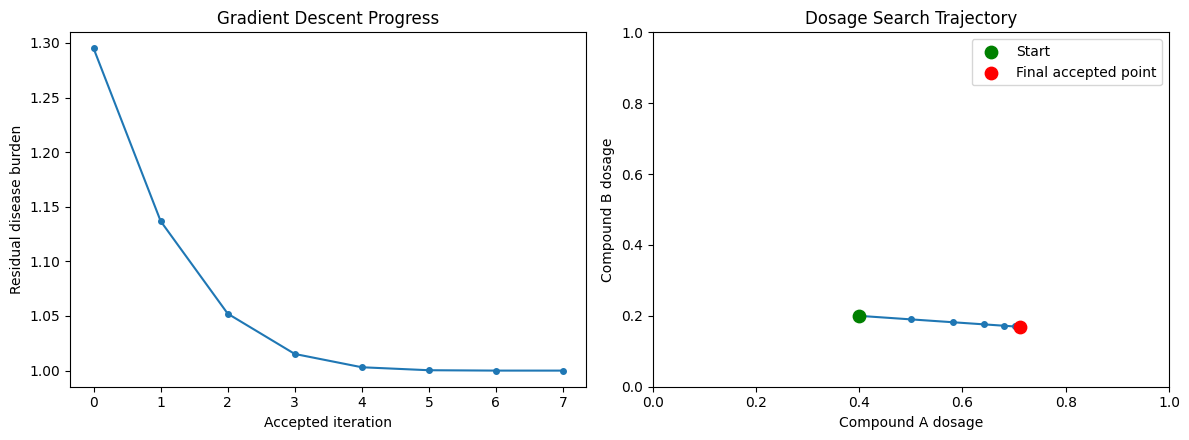

In [ ]:
history = result["history"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot disease burden along the accepted optimization trajectory.
axes[0].plot(
    history["iteration"],
    history["burden"],
    marker="o",
    markersize=4
)

axes[0].set_xlabel("Accepted iteration")
axes[0].set_ylabel("Residual disease burden")
axes[0].set_title("Gradient Descent Progress")

# Plot the accepted dosage trajectory without querying a background grid.
axes[1].plot(
    history["a"],
    history["b"],
    marker="o",
    markersize=4
)

axes[1].scatter(
    history["a"].iloc[0],
    history["b"].iloc[0],
    color="green",
    s=80,
    label="Start",
    zorder=5
)

axes[1].scatter(
    history["a"].iloc[-1],
    history["b"].iloc[-1],
    color="red",
    s=80,
    label="Final accepted point",
    zorder=5
)

axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Compound A dosage")
axes[1].set_ylabel("Compound B dosage")
axes[1].set_title("Dosage Search Trajectory")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Reuse the existing API client, cache, and Part 2 result.
TOTAL_BUDGET = MAX_QUERIES

starts = [
    [0.25, 0.25],
    [0.25, 0.75],
    [0.75, 0.25],
    [0.75, 0.75]
]

# Reserve requests for checking the final candidate minima.
VALIDATION_RESERVE = 20

# Preserve results if this cell is run again in the same session.
if "multi_results" not in globals():
    multi_results = [{
        "start_a": float(result["history"]["a"].iloc[0]),
        "start_b": float(result["history"]["b"].iloc[0]),
        "output": result,
        "new_queries": result["queries"]
    }]

completed_starts = {
    (item["start_a"], item["start_b"])
    for item in multi_results
}

pending_starts = [
    point for point in starts
    if tuple(point) not in completed_starts
]

for index, point in enumerate(pending_starts):
    available = (
        TOTAL_BUDGET
        - api.query_count
        - VALIDATION_RESERVE
    )

    remaining_starts = len(pending_starts) - index
    run_allowance = available // remaining_starts

    if run_allowance < 4:
        print("Insufficient remaining search budget.")
        break

    before = api.query_count

    # Give each remaining start a fair share of the search budget.
    api.max_queries = min(
        TOTAL_BUDGET,
        before + run_allowance
    )

    try:
        output = gradient_descent(api, point)
    finally:
        api.max_queries = TOTAL_BUDGET

    multi_results.append({
        "start_a": point[0],
        "start_b": point[1],
        "output": output,
        "new_queries": api.query_count - before
    })

    print(
        f"Start {point}: "
        f"E = {output['burden']:.6f}, "
        f"new requests = {api.query_count - before}, "
        f"stop = {output['stop_reason']}"
    )

print(f"\nTotal API requests so far: {api.query_count}")

Start [0.25, 0.25]: E = 1.100000, new requests = 39, stop = API query budget reached
Start [0.25, 0.75]: E = 1.100000, new requests = 33, stop = Projected gradient tolerance reached
Start [0.75, 0.25]: E = 1.000000, new requests = 15, stop = Projected gradient tolerance reached
Start [0.75, 0.75]: E = 1.100000, new requests = 42, stop = Projected gradient tolerance reached

Total API requests so far: 153


In [ ]:
summary_rows = []

for run_id, item in enumerate(multi_results):
    output = item["output"]

    summary_rows.append({
        "run": run_id,
        "start_a": item["start_a"],
        "start_b": item["start_b"],
        "final_a": output["a"],
        "final_b": output["b"],
        "burden": output["burden"],
        "new_queries": item["new_queries"],
        "stop_reason": output["stop_reason"]
    })

multi_summary = pd.DataFrame(summary_rows)

display(multi_summary.round(6))

# Group nearby endpoints using an illustrative coordinate tolerance.
CLUSTER_DISTANCE = 0.01
representatives = []

for row in multi_summary.sort_values("burden").to_dict("records"):
    point = np.array([row["final_a"], row["final_b"]])

    if all(
        np.linalg.norm(
            point - np.array([rep["final_a"], rep["final_b"]])
        ) > CLUSTER_DISTANCE
        for rep in representatives
    ):
        representatives.append(row)

candidate_table = pd.DataFrame(representatives)

print("Distinct candidate endpoints:")
display(candidate_table.round(6))

,run,start_a,start_b,final_a,final_b,burden,new_queries,stop_reason
0,0,0.40,0.20,0.711844,0.168961,1.0,24,Projected gradient tolerance reached
1,1,0.25,0.25,0.215994,0.688379,1.1,39,API query budget reached
2,2,0.25,0.75,0.216127,0.689268,1.1,33,Projected gradient tolerance reached
3,3,0.75,0.25,0.711929,0.168905,1.0,15,Projected gradient tolerance reached
4,4,0.75,0.75,0.216382,0.688999,1.1,42,Projected gradient tolerance reached


Distinct candidate endpoints:


,run,start_a,start_b,final_a,final_b,burden,new_queries,stop_reason
0,3,0.75,0.25,0.711929,0.168905,1.0,15,Projected gradient tolerance reached
1,2,0.25,0.75,0.216127,0.689268,1.1,33,Projected gradient tolerance reached


In [ ]:
# Check the two lowest-burden distinct candidates.
NEIGHBOR_RADIUS = 0.002
SCORE_TOL = 1e-8

validation_rows = []

for candidate in representatives[:2]:
    # Keep the validation within the shared request budget.
    if api.query_count + 10 > TOTAL_BUDGET:
        print("Insufficient budget to complete candidate validation.")
        break

    x = np.array([
        candidate["final_a"],
        candidate["final_b"]
    ])

    value = candidate["burden"]

    gradient = estimate_gradient(api, x, value)

    projected_residual = np.linalg.norm(
        x - np.clip(x - gradient, LOWER, UPPER)
    )

    neighbor_values = []

    for da in [-NEIGHBOR_RADIUS, 0.0, NEIGHBOR_RADIUS]:
        for db in [-NEIGHBOR_RADIUS, 0.0, NEIGHBOR_RADIUS]:
            if da == 0.0 and db == 0.0:
                continue

            neighbor = np.clip(
                x + np.array([da, db]),
                LOWER,
                UPPER
            )

            neighbor_values.append(api.evaluate(neighbor))

    lowest_neighbor = min(neighbor_values)

    neighborhood_passed = (
        lowest_neighbor >= value - SCORE_TOL
    )

    stationary = projected_residual <= GRAD_TOL

    validation_rows.append({
        "a": x[0],
        "b": x[1],
        "burden": value,
        "projected_residual": projected_residual,
        "neighborhood_passed": neighborhood_passed,
        "validated": stationary and neighborhood_passed
    })

validation_table = pd.DataFrame(validation_rows)

if not validation_table.empty:
    display(validation_table.round(8))

    optima_table = (
        validation_table[validation_table["validated"]]
        .sort_values("burden")
        .copy()
    )

    if len(optima_table) == 2:
        optima_table["classification"] = [
            "Global-minimum candidate",
            "Local-minimum candidate"
        ]

        report = optima_table[
            ["classification", "a", "b", "burden"]
        ]

        print("Markdown results table:\n")
        print(report.to_markdown(index=False, floatfmt=".6f"))

    else:
        print(
            "Two validated distinct minima were not established. "
            "Inspect the stopping reasons and validation results "
            "before assigning global/local labels."
        )

print(f"\nTotal API requests: {api.query_count}/{TOTAL_BUDGET}")

,a,b,burden,projected_residual,neighborhood_passed,validated
0,0.711929,0.168905,1.0,0.000301,True,True
1,0.216127,0.689268,1.1,0.000728,True,True


Markdown results table:

| classification           |        a |        b |   burden |
|:-------------------------|---------:|---------:|---------:|
| Global-minimum candidate | 0.711929 | 0.168905 | 1.000000 |
| Local-minimum candidate  | 0.216127 | 0.689268 | 1.100000 |

Total API requests: 169/200


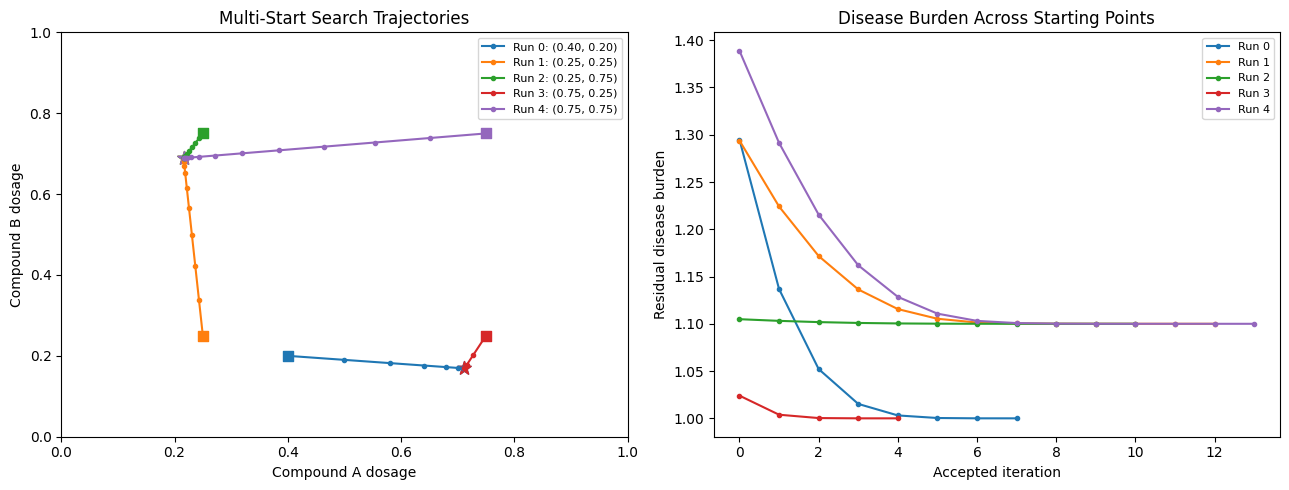

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for run_id, item in enumerate(multi_results):
    history = item["output"]["history"]
    label = (
        f"Run {run_id}: "
        f"({item['start_a']:.2f}, {item['start_b']:.2f})"
    )

    line, = axes[0].plot(
        history["a"],
        history["b"],
        marker=".",
        label=label
    )

    axes[0].scatter(
        history["a"].iloc[0],
        history["b"].iloc[0],
        marker="s",
        color=line.get_color(),
        s=45
    )

    axes[0].scatter(
        history["a"].iloc[-1],
        history["b"].iloc[-1],
        marker="*",
        color=line.get_color(),
        s=100
    )

    axes[1].plot(
        history["iteration"],
        history["burden"],
        marker=".",
        label=f"Run {run_id}"
    )

axes[0].set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Compound A dosage",
    ylabel="Compound B dosage",
    title="Multi-Start Search Trajectories"
)

axes[1].set(
    xlabel="Accepted iteration",
    ylabel="Residual disease burden",
    title="Disease Burden Across Starting Points"
)

axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()